# South Barnegat Bay Onshore Wind Model Prediction with the Use of Long Short-Term Memory Neural Networks - Graphing

In [86]:
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

In [87]:
import matplotlib as mpl
#mpl.rcParams["font.family"] = "sans-serif"
#mpl.rcParams["font.sans-serif"] = ["Times New Roman"]  # or another installed font
#mpl.rcParams["font.size"] = 12
mpl.rcdefaults()

In [88]:
myfont = {'fontname':'Georgia'}

In [89]:
#Open data as csv
data = pd.read_csv("lstm_predictions.csv")



### Actual VS Predicted Data

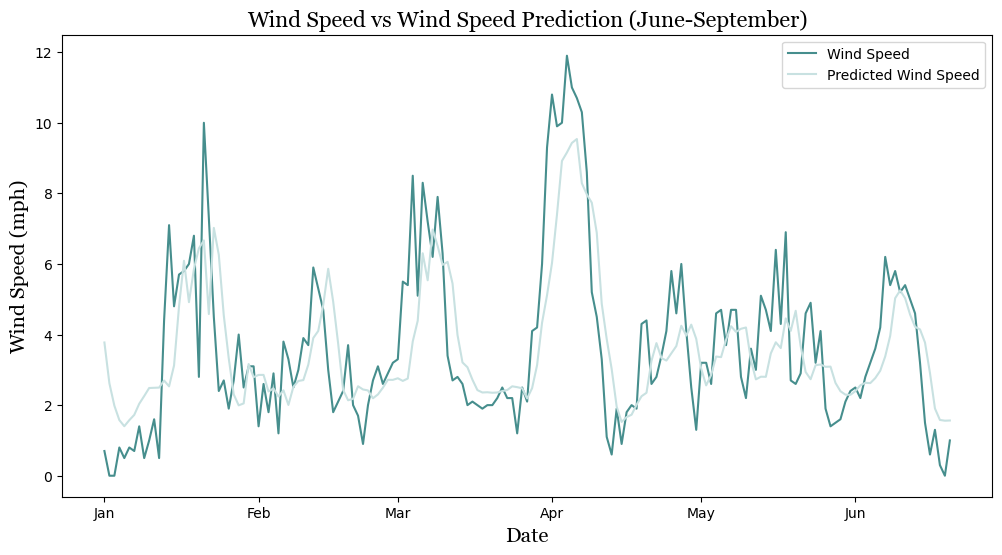

In [90]:
#Plot 14 - Wind Speed VS Wind Speed Prediction


plt.figure(figsize=(12,6))
plt.plot(data['Date'], data['target_actual'], label='Wind Speed', color='#468e8d')
plt.plot(data['Date'], data['target_predicted'], label='Predicted Wind Speed', color='#c8e1e1')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())          # one tick per month
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.title("Wind Speed vs Wind Speed Prediction (June-September)", **myfont, fontsize=16)
plt.xlabel('Date', **myfont, fontsize=15)
plt.ylabel('Wind Speed (mph)', **myfont, fontsize=15)
plt.legend()

In [91]:
#Plot 15 - Wind Gust Speed VS Wind Gust Speed Prediction


plt.figure(figsize=(12,6))
plt.plot(data_p['Date'], data_p['Gusting'], label='Wind Gusting Speed', color='#468e8d')
plt.plot(data_p['Date'], data_p['wind_gust_pred_linear'], label='Predicted Gusting Wind Speed', color='#c8e1e1')
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator())          # one tick per month
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.title("Wind Gusting Speed vs Wind Gusting Speed Prediction (June-September)", **myfont, fontsize=16)
plt.xlabel('Date', **myfont, fontsize=15)
plt.ylabel('Wind Gusting Speed (mph)', **myfont, fontsize=15)
plt.legend()


NameError: name 'data_p' is not defined

<Figure size 1200x600 with 0 Axes>

In [ ]:
print(data_p['wind_direction_pred_naive'].dtype)

float64


In [ ]:
#Convert predicted directions back to labels
#replace the direction column with the corresponding degree values
direction_map = { 0: 'N', 1: 'NNE', 2: 'NE', 3: 'ENE', 4: 'E', 5: 'ESE', 6: 'SE', 7: 'SSE',
8: 'S', 9: 'SSW', 10: 'SW', 11: 'WSW', 12: 'W', 13: 'WNW', 14: 'NW', 15: 'NNW'
}

data_p['Direction (A)'] = data_p['Direction (A)'].replace(direction_map).infer_objects(copy = False)

data_p['wind_direction_pred_label'] = data_p['wind_direction_pred_naive'].map(direction_map)
data_p.tail()

,Date,Mainland Air Temp,Humidity (%),Direction (A),Wind Speed (A),Gusting,Atmospheric Pressure (IN),Precipitation Rate,Bay Temp,Salinity,...,Ocean Temp,Onshore,upwelling_flag,upwelling_pred_naive,onshore_pred_direction,wind_direction_pred_naive,wind_speed_pred_linear,wind_gust_pred_linear,Wind_pred_warning,wind_direction_pred_label
2732,2025-09-23 20:00:00,21.2,88.0,N,6.0,9.1,29.96,0.0,21.84,30.30,...,21.3,0,0,0.0,0.0,0.0,5.2,10.3,True,N
2733,2025-09-23 21:00:00,20.9,89.0,SSW,4.2,6.4,29.96,0.0,21.61,29.96,...,21.3,0,0,0.0,0.0,0.0,3.6,7.3,False,N
2734,2025-09-23 22:00:00,21.4,83.0,SSW,4.5,7.5,29.96,0.0,22.02,30.06,...,21.3,0,0,0.0,0.0,9.0,4.2,7.9,False,SSW
2735,2025-09-23 23:00:00,21.5,84.0,SW,3.8,5.3,29.97,0.0,22.09,30.03,...,21.3,0,0,0.0,0.0,9.0,3.0,6.8,False,SSW
2736,2025-09-24 00:00:00,20.7,89.0,SSW,1.8,3.6,29.97,0.0,22.11,30.04,...,21.3,0,0,0.0,0.0,10.0,2.0,3.7,False,SW
